# Decision Tree

**Decision trees** make predictions by asking a series of yes/no questions about feature values. Each question splits the data into two groups, and the process repeats until we reach a final prediction (a leaf node).

Each question partitions the data into two groups. This is called **recursive splitting** because the exact same process — find the best question, split the data — repeats at every node.

**recursive** means repeating the same process at each step.At every node, the tree:

- Examines all remaining data in that subtree
- Tries every possible feature and every possible threshold
- Finds the one split that most reduces Gini impurity (covered in Part 5)
- Divides data into two groups
- Repeats on each group independently until a stopping condition is met
- The stopping conditions are:

    - Node is pure (Gini = 0, all one class) — no further splitting can improve purity
    - Node has too few samples (controlled by min_samples_split) — prevents splitting on tiny subgroups
    - Tree has reached maximum depth (max_depth parameter) — the primary regularization control




### Logistic regression: One global boundary
Imagine you want to predict whether a patient has diabetes based on their glucose level.

Logistic regression learns a mathematical relationship between glucose level and the probability of having diabetes.

It then uses a decision threshold (for example, 0.5) to classify patients.

For example:
- Probability ≥ 0.5 → Diabetic (1)
- Probability < 0.5 → Not diabetic (0)

It uses one global decision rule across the dataset.

![logistic](../images/Screenshot%202026-11-11%20at%2007.00.15.png)


  

### Decision tree: Many local boundaries
A decision tree does not make all its decisions using one mathematical boundary.

Instead, it asks a series of questions.

Imagine predicting diabetes using glucose level, BMI and age.

Notice what is happening:
1. The first question divides all patients into two groups.
2. The second question only applies to patients whose glucose level was above 125.
3. The third question only applies to patients whose glucose level was 125 or below.
Each question creates a separate decision boundary.

These are called local boundaries because each boundary applies only to the subset of patients that reaches that particular node.

**The flexibility is a double-edged sword**. With no depth limit, a tree will create separate rules for every individual training example — achieving 100% training accuracy but predicting nonsense on new data (overfitting). max_depth is the critical regularization parameter that prevents this.

**Regularization** is a technique in machine learning used to prevent a model from becoming too complex and overfitting the training data. It does this by adding a penalty to the loss function, discouraging overly complex models and helping them generalize better to unseen data.

**A loss function** is a mathematical function used in machine learning to measure how far a model's predictions are from the actual values.

### Parameters
Parameters are values that a machine learning model learns automatically from the training data during training.

Examples:
- Weights (coefficients)
- Bias (intercept)
For example, in linear regression, the model learns the slope and intercept.
### Hyperparameters
Hyperparameters are settings that you configure before training or control during the training process to influence how the model learns.

Examples:
- Learning rate
- Number of epochs
- Maximum tree depth
- Regularization strength (Lambda)
- Number of neighbours (K) in KNN

max_depth is a hyperparameter that limits how deep the tree can grow. It directly controls whether the tree underfits or overfits.



## Bias-Variance Tradeoff
The Bias-Variance Tradeoff is a concept in machine learning that explains the balance between two types of errors a model can make: bias and variance.

The goal is to find a model that learns patterns well without being too simple or too complex.

### Bias
Bias is the error that occurs when a model makes overly simple assumptions about the data and fails to capture the underlying patterns.

This is associated with underfitting.

For example, imagine you're predicting house prices using house size, location and number of bedrooms.

If you use a model that is too simple, it might fail to capture important relationships between these features and house prices.
- High bias
- Oversimplified model
- Underfitting
- Poor performance on training and test data

### Variance
Variance describes how sensitive a model is to changes in its training data.

A model with high variance learns the training data too closely, including noise and random patterns.

This is associated with overfitting.

For example, imagine training a decision tree to predict house prices without limiting its depth.

The tree might learn very specific rules that work well on training data but fail when predicting prices for new houses.
- High variance
- Overly complex model
- Overfitting
- Good training performance but poor test performance

### The tradeoff
The bias-variance tradeoff means finding the right balance between model simplicity and model complexity.

## Gini Impurity
How does a decision tree decide which feature to split on and at what threshold? It uses Gini impurity to measure the quality of each potential split.
At each node, the tree evaluates every possible split and picks the one that most reduces total Gini impurity.

#### Intuition: Pure vs Mixed Groups

Imagine sorting buildings into two buckets based on a rule:

Rule: "foundation_type ≤ 2"

Bucket 1 (YES — weak foundations, 350 buildings):
  300 severe, 50 not severe
  → Mostly one class → RELATIVELY PURE

Bucket 2 (NO — strong foundations, 150 buildings):
  0 severe, 150 not severe
  → All one class → COMPLETELY PURE (Gini = 0!)
A pure bucket (all one class) gives confident predictions. A mixed bucket is uncertain.

## The Class Imbalance Problem

What happens when one class is much rarer than the other?

Example: 1% of buildings have a rare foundation type. A model that ignores this type and predicts "other" for every building gets 99% accuracy — but it captures 0% of that rare foundation type correctly.

In our Nepal dataset: 64% severe vs 36% not severe — a mild imbalance. Both models handle this acceptably by default. But in more extreme cases (e.g., 95% vs 5%), both logistic regression and decision trees default to predicting the majority class too often.
**Fixes (same for both models)**:
1. class_weight='balanced':It automatically assigns higher weights to the minority class and lower weights to the majority class when calculating the model's loss.
2. Threshold adjustment: lower the decision threshold from 0.5 to 0.3 to flag more minority-class cases
3. Oversampling (SMOTE): synthetically generate minority-class training examples


In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from duckdb_wrangle import wrangle_nepal_data
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from category_encoders import OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import accuracy_score


In [12]:
df=wrangle_nepal_data('../data',district_id=4)
df

,district_id,age_building,plinth_area_sq_ft,height_ft_pre_eq,foundation_type,ground_floor_type,severe_damage
building_id,,,,,,,
196904,4,15,484,15,Other,Brick/Stone,1
196906,4,11,347,14,Other,Brick/Stone,1
196915,4,50,247,14,Other,Brick/Stone,1
196920,4,6,798,16,Other,Brick/Stone,1
196942,4,10,400,14,Other,Brick/Stone,1
...,...,...,...,...,...,...,...
196740,4,15,280,18,Mud mortar-Stone/Brick,Mud,1
196776,4,60,231,13,Other,Mud,1
196793,4,15,625,18,Other,Mud,1


Separate target and features

In [13]:
target="severe_damage"
features=[col for col in df.columns if col != target]

Create X and Y

In [14]:
X=df[features]
y=df[target]

### Three way splitting
#### Why we need three sets
1. train set : fit the model
2. validation set: tune the hyperparameters
3. test set : final evaluation

The problem with two-way splits for hyperparameter tuning:

If we chose max_depth based on test set accuracy, we would be fitting to the test set — a form of data leakage. Every time we try a new max_depth and check the test accuracy, we're implicitly using test information to make modeling decisions.

In [15]:
# first split
X_train_val,X_test,y_train_val,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

# second split
X_train,X_val,y_train,y_val=train_test_split(X_train_val,y_train_val,test_size=0.25,random_state=42)

print(f"Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X):.1%})")
print(f"Validation set: {X_val.shape[0]} samples ({X_val.shape[0]/len(X):.1%})")
print(f"Test set: {X_test.shape[0]} samples ({X_test.shape[0]/len(X):.1%})")

Training set: 42501 samples (60.0%)
Validation set: 14167 samples (20.0%)
Test set: 14168 samples (20.0%)


Baseline

In [16]:
baseline_acc=y_train.value_counts(normalize=True).max()
baseline_acc
print(f"Baseline Accuracy: {baseline_acc:.4f}")
print(f"Majority class: {y_train.value_counts().idxmax()}")

Baseline Accuracy: 0.6435
Majority class: 1


Decision Tree

In [17]:
model = Pipeline([
    ("encoder",OrdinalEncoder()),
    ("model",DecisionTreeClassifier(max_depth=6,random_state=42))
])

model.fit(X_train,y_train)

train_acc=accuracy_score(y_train,model.predict(X_train))
val_acc=accuracy_score(y_val,model.predict(X_val))

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Baseline Accuracy: {baseline_acc:.4f}")

Training Accuracy: 0.7143
Validation Accuracy: 0.7085
Baseline Accuracy: 0.6435


### Hyperparameter tuning

In [ ]:
depths=range(1,16)
train_accuracies=[]
val_accuracies=[]

for depth in depths:
    model=Pipeline([
        ("encoder",OrdinalEncoder()),
        ("tree",DecisionTreeClassifier(max_depth=depth,random_state=42))
    ])
    model.fit(X_train,y_train)
    train_acc=accuracy_score(y_train,model.predict(X_train))
    val_acc=accuracy_score(y_val,model.predict(X_val))
    
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)
    
print("Hyperparameter tuning completed")
print(f"best validation accuracy: {max(val_accuracies)} at depth {list(depths)[val_accuracies.index(max(val_accuracies))]}")

Hyperparameter tuning completed
best validation accuracy: 0.7084774475894685 at depth 6


Validation curve

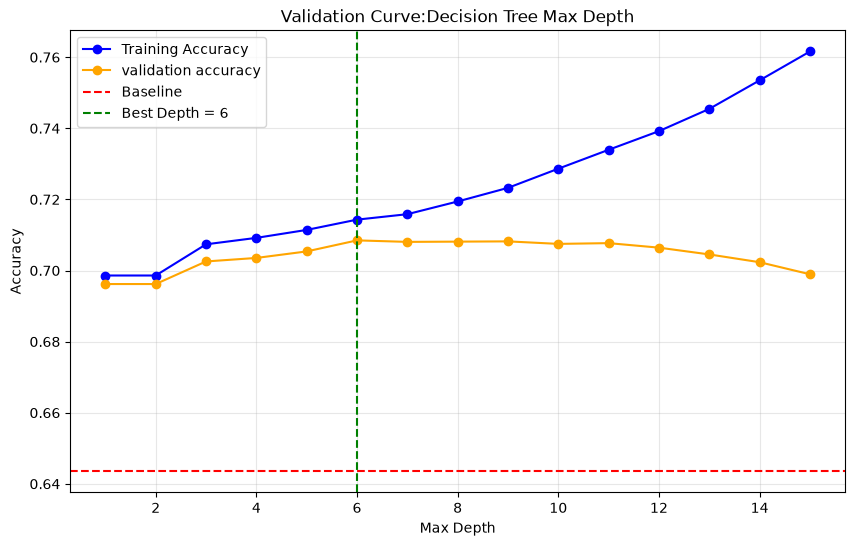

In [27]:
best_depth=list(depths)[val_accuracies.index(max(val_accuracies))]

fig,ax=plt.subplots(figsize=(10,6))
ax.plot(depths,train_accuracies,'o-',label="Training Accuracy",color='blue')
ax.plot(depths,val_accuracies,'o-',label="validation accuracy",color="orange")
ax.axhline(y=baseline_acc,color='red',linestyle='--',label='Baseline')
ax.axvline(x=best_depth,color="green",linestyle="--",label=f"Best Depth = {best_depth}")
ax.set_xlabel('Max Depth')
ax.set_ylabel("Accuracy")
ax.set_title("Validation Curve:Decision Tree Max Depth")
ax.legend()
ax.grid(True,alpha=0.3)
plt.show()


final model

In [28]:
final_model=Pipeline([
    ("encoder",OrdinalEncoder()),
    ("model",DecisionTreeClassifier(max_depth=best_depth,random_state=42))
])

final_model.fit(X_train_val,y_train_val)
test_acc=accuracy_score(y_test,model.predict(X_test))

print(f"\nFinal Model Performance:")
print(f"Training Accuracy: {accuracy_score(y_train, final_model.predict(X_train)):.4f}")
print(f"Validation Accuracy: {accuracy_score(y_val, final_model.predict(X_val)):.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Baseline Accuracy: {baseline_acc:.4f}")


Final Model Performance:
Training Accuracy: 0.7153
Validation Accuracy: 0.7129
Test Accuracy: 0.6914
Baseline Accuracy: 0.6435


#### Feature importance in Decision Trees
Feature importance tells you how much a feature contributes to reducing impurity when the tree makes splits using that feature.

In [33]:
importances=final_model.named_steps['model'].feature_importances_
feature_names=final_model.named_steps['encoder'].get_feature_names_out()

feature_importance=pd.Series(importances,index=feature_names).sort_values(ascending=False)
feature_importance

foundation_type      0.628068
ground_floor_type    0.171863
height_ft_pre_eq     0.104706
age_building         0.065657
plinth_area_sq_ft    0.029705
district_id          0.000000
dtype: float64

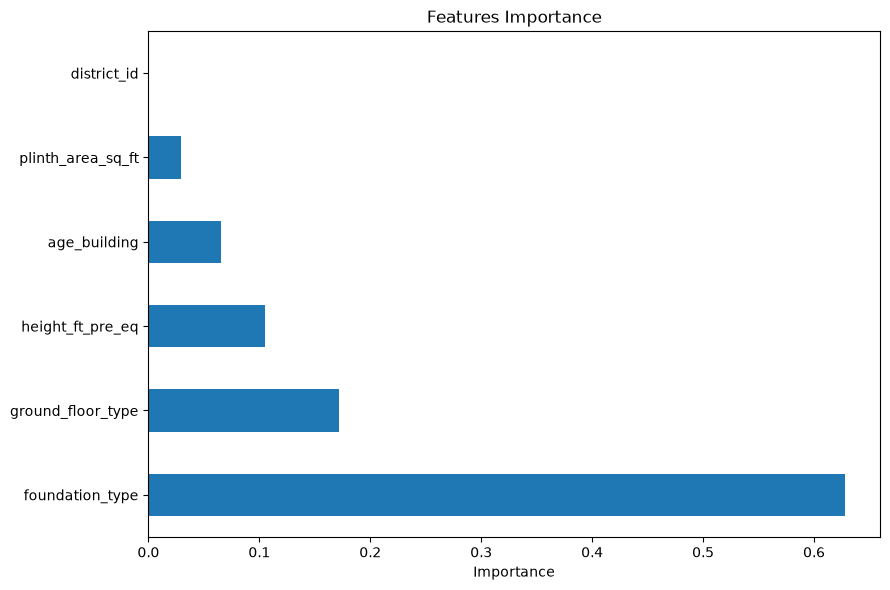

In [35]:
fig,ax=plt.subplots(figsize=(9,6))
feature_importance.plot(kind="barh",ax=ax)
ax.set_xlabel('Importance')
ax.set_title("Features Importance")
plt.tight_layout()
plt.show()

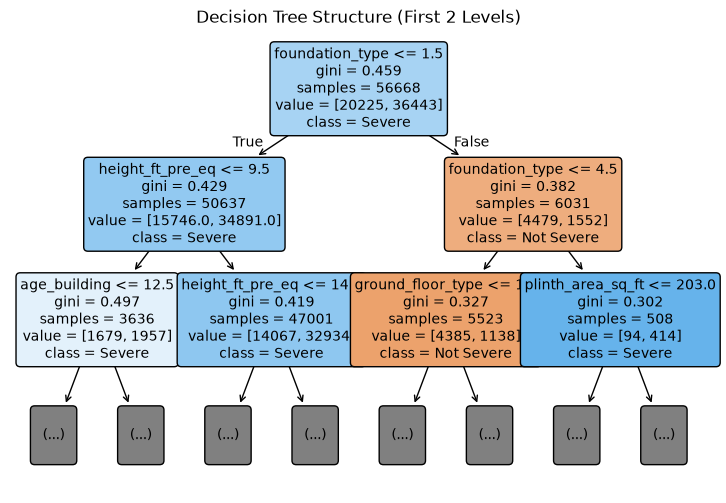

In [38]:
fig,ax=plt.subplots(figsize=(9,6))
plot_tree(
    final_model.named_steps["model"],
    feature_names=feature_names,
    class_names=["Not Severe","Severe"],
    filled=True,
    rounded=True,
    max_depth=2,
    ax=ax,
    fontsize=10
)
ax.set_title('Decision Tree Structure (First 2 Levels)')
plt.show()